# Notebook 15 — CHIRPS daily timing, pentad redistribution and accumulation diagnostics

**Research question:** Does the daily disagreement between gauges and CHIRPS v2/v3 arise partly from mismatches in daily rainfall allocation within multi-day totals?

**Important:** Improved pentad or monthly agreement does **not** by itself prove the temporal redistribution algorithm is responsible. Aggregation smooths weather variability, and point gauges differ from gridded estimates. This notebook separates *amount* and *within-pentad allocation* diagnostics, and assesses day-to-day alignment using lagged correlations and a clearly labelled diagnostic timing-tolerance test.

**No calibration model is fitted.** Analyses below are **diagnostic, not predictive corrections**. The 1995–2000 window has been inspected in previous notebooks; do not call it a pristine untouched test. Results are written to a new numbered output directory; no previous notebooks or outputs are modified.

### What you will obtain
1. Matched station-date checks, using the same files and station names as Notebook 14.
2. Daily lag correlations (−3 through +3 days), comparing v2/v3 on identical valid observations.
3. Complete CHIRPS-style calendar pentad (1–5, 6–10, ..., 26–end of month) comparisons.
4. Within-pentad **daily rainfall fraction** diagnostics, including temporal allocation MAE and daily peak offset.
5. Weekly and monthly aggregates, including normalized cumulative fractions for complete calendar years.
6. Report-ready figures and CSVs in an automatically unique run folder.


## 1. Setup and file paths — run from your project `notebooks/` folder

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
from IPython.display import display
from datetime import datetime
from uuid import uuid4

here=Path.cwd().resolve()
PROJECT_DIR=next((p for p in (here, here.parent) if (p/'data'/'processed').is_dir()), here.parent if here.name.lower()=='notebooks' else here)
BUFFER_DIR=PROJECT_DIR/'data'/'chirps'/'buffered'
GAUGE_FILE=PROJECT_DIR/'data'/'processed'/'Ground_CHIRPS_Paired_1981_2000.csv'
OUTPUT_ROOT=PROJECT_DIR/'results'/'15_Temporal_Redistribution_Diagnostics'
COLS=['Point_mm','Buffer5km_mm','Buffer10km_mm']
START='1995-01-01'
END='2000-12-31'
# The *point* is the primary product comparison; buffers are optional diagnostic repeats.
METHODS=['Point_mm','Buffer5km_mm','Buffer10km_mm']
print('Project:', PROJECT_DIR)
print('Input folder:', BUFFER_DIR)
print('Reporting window:', START, 'to', END)


Project: C:\Users\Asini Perera\CP Lab 1\CP Lab 2\Sri Lanka Rain Fall Reserach
Input folder: C:\Users\Asini Perera\CP Lab 1\CP Lab 2\Sri Lanka Rain Fall Reserach\data\chirps\buffered
Reporting window: 1995-01-01 to 2000-12-31


## 2. Load exactly the same matched gauge, v2 and v3 daily observations as Notebook 14

In [3]:
def load_version(version):
    files=sorted(BUFFER_DIR.glob(f'CHIRPS_Buffer_{version}_*.csv'))
    year_names=[f.stem.split('_')[-1] for f in files]
    expected={str(y) for y in range(1981,2001)}
    if set(year_names)!=expected or len(files)!=20:
        raise FileNotFoundError(f'{version}: expected 20 unique annual CSVs 1981–2000 in {BUFFER_DIR}; missing={sorted(expected-set(year_names))}; extra={sorted(set(year_names)-expected)}')
    f=pd.concat([pd.read_csv(p,usecols=['Date','Station']+COLS) for p in files],ignore_index=True)
    f['Date']=pd.to_datetime(f['Date'],errors='coerce')
    f['Station']=f['Station'].astype(str).str.strip().replace({'Nuwaraeliya':'Nuwara Eliya'})
    for x in COLS:f[x]=pd.to_numeric(f[x],errors='coerce')
    if f.Date.isna().any():raise ValueError(f'{version}: invalid dates')
    if f.duplicated(['Date','Station']).any():raise ValueError(f'{version}: duplicate station-date rows')
    f=f.rename(columns={x:f'{version}_{x}' for x in COLS})
    print(f'{version}: {len(f):,} rows; {f.Date.min().date()} to {f.Date.max().date()}')
    return f
v2=load_version('v2')
v3=load_version('v3rnl')
if not GAUGE_FILE.is_file():raise FileNotFoundError(f'Run Notebook 03: {GAUGE_FILE}')
gauge=pd.read_csv(GAUGE_FILE,usecols=['Date','Station','Rainfall_mm'])
gauge['Date']=pd.to_datetime(gauge['Date'],errors='coerce')
gauge['Station']=gauge['Station'].astype(str).str.strip().replace({'Nuwaraeliya':'Nuwara Eliya'})
gauge['Rainfall_mm']=pd.to_numeric(gauge['Rainfall_mm'],errors='coerce')
if gauge.duplicated(['Date','Station']).any():raise ValueError('Gauge station-date duplicates')
allcols=[f'{v}_{x}' for v in ('v2','v3rnl') for x in COLS]
matched=gauge.merge(v2,on=['Date','Station'],validate='one_to_one').merge(v3,on=['Date','Station'],validate='one_to_one')
matched=matched.dropna(subset=['Date','Rainfall_mm']+allcols).copy()
matched=matched[(matched.Rainfall_mm>=0)&matched[allcols].ge(0).all(axis=1)].copy()
matched=matched.sort_values(['Station','Date']).reset_index(drop=True)
assert not matched.duplicated(['Station','Date']).any()
print('Both versions + gauge matched valid station-days:',len(matched))
display(matched.groupby('Station').agg(Days=('Date','size'),First=('Date','min'),Last=('Date','max')))


v2: 43,830 rows; 1981-01-01 to 2000-12-31
v3rnl: 43,830 rows; 1981-01-01 to 2000-12-31
Both versions + gauge matched valid station-days: 43737


,Days,First,Last
Station,,,
Badulla,7300,1981-01-01,2000-12-31
Colombo,7279,1981-01-01,2000-12-31
Galle,7291,1981-01-01,2000-12-31
Kandy,7296,1981-01-01,2000-12-31
Nuwara Eliya,7278,1981-01-01,2000-12-31
Puttalam,7293,1981-01-01,2000-12-31


## 3. Define evaluation window and functions

For gauge \(G_t\) and satellite estimate \(S_t\), the same-day Pearson correlation is \(r_0=\operatorname{corr}(G_t,S_t)\). For a lag \(\ell\), we evaluate \(r_\ell=\operatorname{corr}(G_t,S_{t+\ell})\). **Positive lag means the satellite value is taken from a later date than the gauge value.** The code pairs actual calendar dates after shifting; it never silently treats observations separated by a missing day as adjacent. A *maximum* lagged correlation is an exploratory diagnostic, not a fair replacement for zero-lag performance.


In [5]:
test=matched.loc[matched.Date.between(START,END)].copy()
assert len(test)>0, 'No valid rows in reporting window'
def pearson(y,x):
    y=np.asarray(y,float); x=np.asarray(x,float)
    return float(np.corrcoef(y,x)[0,1]) if len(y)>2 and np.std(y)>0 and np.std(x)>0 else np.nan

def measures(y,x):
    y=np.asarray(y,float);x=np.asarray(x,float);e=x-y
    return {'N':len(y),'Bias':float(e.mean()), 'MAE':float(np.mean(abs(e))),
            'RMSE':float(np.sqrt(np.mean(e*e))), 'Pearson':pearson(y,x),
            'Spearman':float(spearmanr(y,x).statistic) if len(y)>2 and np.std(y)>0 and np.std(x)>0 else np.nan}

print('Matched study rows in this window:',len(test))
display(test.groupby('Station').agg(Days=('Date','size'),First=('Date','min'),Last=('Date','max')))


Matched study rows in this window: 13134


,Days,First,Last
Station,,,
Badulla,2191,1995-01-01,2000-12-31
Colombo,2191,1995-01-01,2000-12-31
Galle,2192,1995-01-01,2000-12-31
Kandy,2190,1995-01-01,2000-12-31
Nuwara Eliya,2180,1995-01-01,2000-12-31
Puttalam,2190,1995-01-01,2000-12-31


## 4. Lagged daily rainfall correlations: ±3 days; no day shifting used for calibration

In [7]:
lag_rows=[]
for station, d in test.groupby('Station'):
    base=d[['Date','Rainfall_mm']].copy()
    for version in ('v2','v3rnl'):
        for method in METHODS:
            satellite=d[['Date',f'{version}_{method}']].copy()
            col=f'{version}_{method}'
            for lag in range(-3,4):
                shifted=satellite.copy()
                # Merge on gauge date to obtain satellite at Date + lag.
                shifted['Date']=shifted['Date']-pd.Timedelta(days=lag)
                pair=base.merge(shifted,on='Date',how='inner',validate='one_to_one')
                lag_rows.append({'Station':station,'Version':version,'Method':method,
                                 'Lag_days':lag,'N':len(pair),
                                 'Pearson':pearson(pair.Rainfall_mm,pair[col])})
lag_scores=pd.DataFrame(lag_rows)
display(lag_scores[lag_scores.Method.eq('Point_mm')].pivot_table(index=['Station','Version'],columns='Lag_days',values='Pearson').round(3))


Lag_days                 -3     -2     -1      0      1      2      3
Station      Version                                                 
Badulla      v2       0.115  0.178  0.202  0.387  0.183  0.152  0.109
             v3rnl    0.117  0.187  0.261  0.456  0.314  0.234  0.175
Colombo      v2       0.146  0.204  0.268  0.369  0.268  0.173  0.121
             v3rnl    0.145  0.202  0.311  0.503  0.318  0.227  0.157
Galle        v2       0.074  0.112  0.207  0.433  0.270  0.126  0.082
             v3rnl    0.140  0.236  0.354  0.482  0.407  0.259  0.187
Kandy        v2       0.125  0.164  0.182  0.334  0.170  0.113  0.079
             v3rnl    0.096  0.173  0.243  0.433  0.282  0.191  0.112
Nuwara Eliya v2       0.120  0.152  0.195  0.357  0.158  0.100  0.083
             v3rnl    0.146  0.205  0.248  0.426  0.313  0.191  0.146
Puttalam     v2       0.175  0.194  0.271  0.461  0.214  0.169  0.182
             v3rnl    0.152  0.208  0.302  0.534  0.403  0.254  0.187

**Interpretation:** If the maximum is near ±1 day instead of zero, the timing hypothesis deserves further investigation. But weather systems persist for multiple days, so peaks at nonzero lags are not definitive evidence of CHIRPS date misassignment. A fixed station-wide shift should *not* be applied based on this test window.

## 5. Make exact CHIRPS-style calendar pentads (last period is 26th–month-end)

In [9]:
def with_pentad(frame):
    x=frame.copy()
    block=np.minimum((x.Date.dt.day.to_numpy()-1)//5,5)
    monthstart=x.Date.dt.to_period('M').dt.start_time
    x['Pentad']=monthstart+pd.to_timedelta(block*5,unit='D')
    x['Expected_Days']=np.where(block==5,x.Date.dt.days_in_month.to_numpy()-25,5)
    return x

def complete_pentad_days(frame):
    x=with_pentad(frame)
    counts=x.groupby(['Station','Pentad'])['Date'].transform('nunique')
    x=x.loc[counts.eq(x.Expected_Days)].copy()
    # Important: excludes partial pentads, including boundary missing dates.
    return x

pentad_days=complete_pentad_days(test)
print('Daily rows in complete pentads:',len(pentad_days))
print('Complete pentads:',pentad_days.groupby(['Station','Pentad']).ngroups)


Daily rows in complete pentads: 13062
Complete pentads: 2574


## 6. Compare complete pentad totals

\(G_P=\sum_{t\in P}G_t\) and \(S_P=\sum_{t\in P}S_t\). Only periods with every day observed in both products and the gauge are included. Pentad total RMSE is in **mm/pentad**, not mm/day.

In [11]:
numeric=['Rainfall_mm']+[f'{v}_{m}' for v in ('v2','v3rnl') for m in METHODS]
pt=pentad_days.groupby(['Station','Pentad'],as_index=False).agg(
    Days=('Date','size'),**{c:(c,'sum') for c in numeric})
pentad_rows=[]
for station, d in pt.groupby('Station'):
    for version in ('v2','v3rnl'):
        for method in METHODS:
            pentad_rows.append({'Station':station,'Version':version,'Method':method,
                                **measures(d.Rainfall_mm,d[f'{version}_{method}'])})
pentad_scores=pd.DataFrame(pentad_rows)
display(pentad_scores.loc[pentad_scores.Method.eq('Point_mm')].round(3))


,Station,Version,Method,N,Bias,MAE,RMSE,Pearson,Spearman
0,Badulla,v2,Point_mm,431,2.994,17.443,25.709,0.650,0.593
3,Badulla,v3rnl,Point_mm,431,2.363,17.272,27.426,0.643,0.606
6,Colombo,v2,Point_mm,431,-1.897,23.941,37.561,0.648,0.662
9,Colombo,v3rnl,Point_mm,431,2.528,24.185,37.214,0.680,0.686
12,Galle,v2,Point_mm,432,-3.489,23.687,38.245,0.595,0.623
15,Galle,v3rnl,Point_mm,432,-0.355,21.472,35.178,0.688,0.655
18,Kandy,v2,Point_mm,430,3.735,21.307,31.528,0.547,0.568
21,Kandy,v3rnl,Point_mm,430,1.026,18.369,28.975,0.588,0.643
24,Nuwara Eliya,v2,Point_mm,420,5.388,22.739,33.262,0.529,0.593
27,Nuwara Eliya,v3rnl,Point_mm,420,-0.729,19.903,30.020,0.556,0.636


## 7. Within-pentad rainfall redistribution fractions

For pentad \(P\), define the fractions \(f^G_t=G_t/G_P\) and \(f^S_t=S_t/S_P\), with \(\sum_{t\in P} f_t=1\). Evaluate \(\mathrm{AllocationMAE}_P=\frac{1}{|P|}\sum_{t\in P}|f_t^S-f_t^G|\). A larger error means that the *relative* rainfall assigned to individual days differs, regardless of pentad amount. **Do not** compute fractions for zero-total or nearly dry pentads: set a minimum wet total for both gauge and satellite. We use 5 mm/pentad as a declared illustrative threshold; test sensitivity to 1 and 10 mm later.

Also calculate the day offset between the maximum daily rainfall within each pentad. This can reveal different intra-pentad peaks but ties/flat profiles reduce interpretability.

In [13]:
MIN_PENTAD_TOTAL_MM=5.0
fraction_rows=[];pentad_allocation_rows=[]
for (station,period),d in pentad_days.groupby(['Station','Pentad'],sort=True):
    total_g=float(d.Rainfall_mm.sum())
    for version in ('v2','v3rnl'):
        for method in METHODS:
            col=f'{version}_{method}'
            total_s=float(d[col].sum())
            if total_g<MIN_PENTAD_TOTAL_MM or total_s<MIN_PENTAD_TOTAL_MM:
                continue
            fg=d.Rainfall_mm.to_numpy()/total_g
            fs=d[col].to_numpy()/total_s
            days=d.Date.dt.day.to_numpy()
            mae=float(np.mean(np.abs(fs-fg)))
            # Ratio of rainfall redistributed differently; total-variation distance 0..1
            tv=float(0.5*np.sum(np.abs(fs-fg)))
            offset=int(days[int(np.argmax(fs))]-days[int(np.argmax(fg))])
            pentad_allocation_rows.append({'Station':station,'Pentad':period,'Version':version,
                'Method':method,'Gauge_Total':total_g,'Sat_Total':total_s,
                'Allocation_MAE':mae,'Total_Variation':tv,'Peak_Offset_days':offset})
            fraction_rows.extend([{'Station':station,'Pentad':period,'Date':dt,'Version':version,
                'Method':method,'Gauge_Fraction':float(g),'Satellite_Fraction':float(s)}
                for dt,g,s in zip(d.Date,fg,fs)])
allocation=pd.DataFrame(pentad_allocation_rows)
fractions=pd.DataFrame(fraction_rows)
allocation_summary=(allocation.groupby(['Station','Version','Method'],as_index=False)
    .agg(Pentads=('Pentad','size'),Allocation_MAE=('Allocation_MAE','mean'),
         Mean_Total_Variation=('Total_Variation','mean'),
         Mean_Abs_Peak_Offset_days=('Peak_Offset_days',lambda s:float(s.abs().mean())),
         Fraction_Same_Peak_Day=('Peak_Offset_days',lambda s:float(s.eq(0).mean()))))
display(allocation_summary.loc[allocation_summary.Method.eq('Point_mm')].round(3))


,Station,Version,Method,Pentads,Allocation_MAE,Mean_Total_Variation,Mean_Abs_Peak_Offset_days,Fraction_Same_Peak_Day
2,Badulla,v2,Point_mm,209,0.203,0.515,1.349,0.335
5,Badulla,v3rnl,Point_mm,202,0.174,0.439,1.050,0.416
8,Colombo,v2,Point_mm,238,0.207,0.523,1.374,0.315
11,Colombo,v3rnl,Point_mm,239,0.180,0.455,1.201,0.364
14,Galle,v2,Point_mm,226,0.212,0.536,1.221,0.363
17,Galle,v3rnl,Point_mm,237,0.171,0.432,0.970,0.401
20,Kandy,v2,Point_mm,210,0.215,0.544,1.376,0.310
23,Kandy,v3rnl,Point_mm,217,0.165,0.418,1.092,0.369
26,Nuwara Eliya,v2,Point_mm,237,0.199,0.506,1.257,0.354
29,Nuwara Eliya,v3rnl,Point_mm,236,0.152,0.386,1.136,0.360


## 8. Daily error and pentad total error within identical complete pentads

If the pentad totals are relatively accurate while individual days have large absolute errors, this suggests mismatch in the daily distribution. We report both rather than inferring causation from correlation alone.

In [14]:
daily_complete_rows=[]
for station,d in pentad_days.groupby('Station'):
    for version in ('v2','v3rnl'):
        for method in METHODS:
            daily_complete_rows.append({'Station':station,'Version':version,'Method':method,
                                        **measures(d.Rainfall_mm,d[f'{version}_{method}'])})
daily_complete_scores=pd.DataFrame(daily_complete_rows)
display(daily_complete_scores.loc[daily_complete_scores.Method.eq('Point_mm')].round(3))


,Station,Version,Method,N,Bias,MAE,RMSE,Pearson,Spearman
0,Badulla,v2,Point_mm,2187,0.590,5.541,11.307,0.387,0.443
3,Badulla,v3rnl,Point_mm,2187,0.466,4.947,10.199,0.456,0.549
6,Colombo,v2,Point_mm,2187,-0.374,7.529,16.200,0.370,0.470
9,Colombo,v3rnl,Point_mm,2187,0.498,7.200,14.540,0.503,0.562
12,Galle,v2,Point_mm,2192,-0.688,7.241,15.223,0.433,0.398
15,Galle,v3rnl,Point_mm,2192,-0.070,6.774,13.747,0.482,0.531
18,Kandy,v2,Point_mm,2182,0.736,6.476,12.766,0.336,0.396
21,Kandy,v3rnl,Point_mm,2182,0.202,5.349,10.814,0.435,0.532
24,Nuwara Eliya,v2,Point_mm,2132,1.061,7.046,12.938,0.362,0.402
27,Nuwara Eliya,v3rnl,Point_mm,2132,-0.144,5.512,10.307,0.428,0.575


## 9. Plot lag curves and normalized within-pentad allocation error

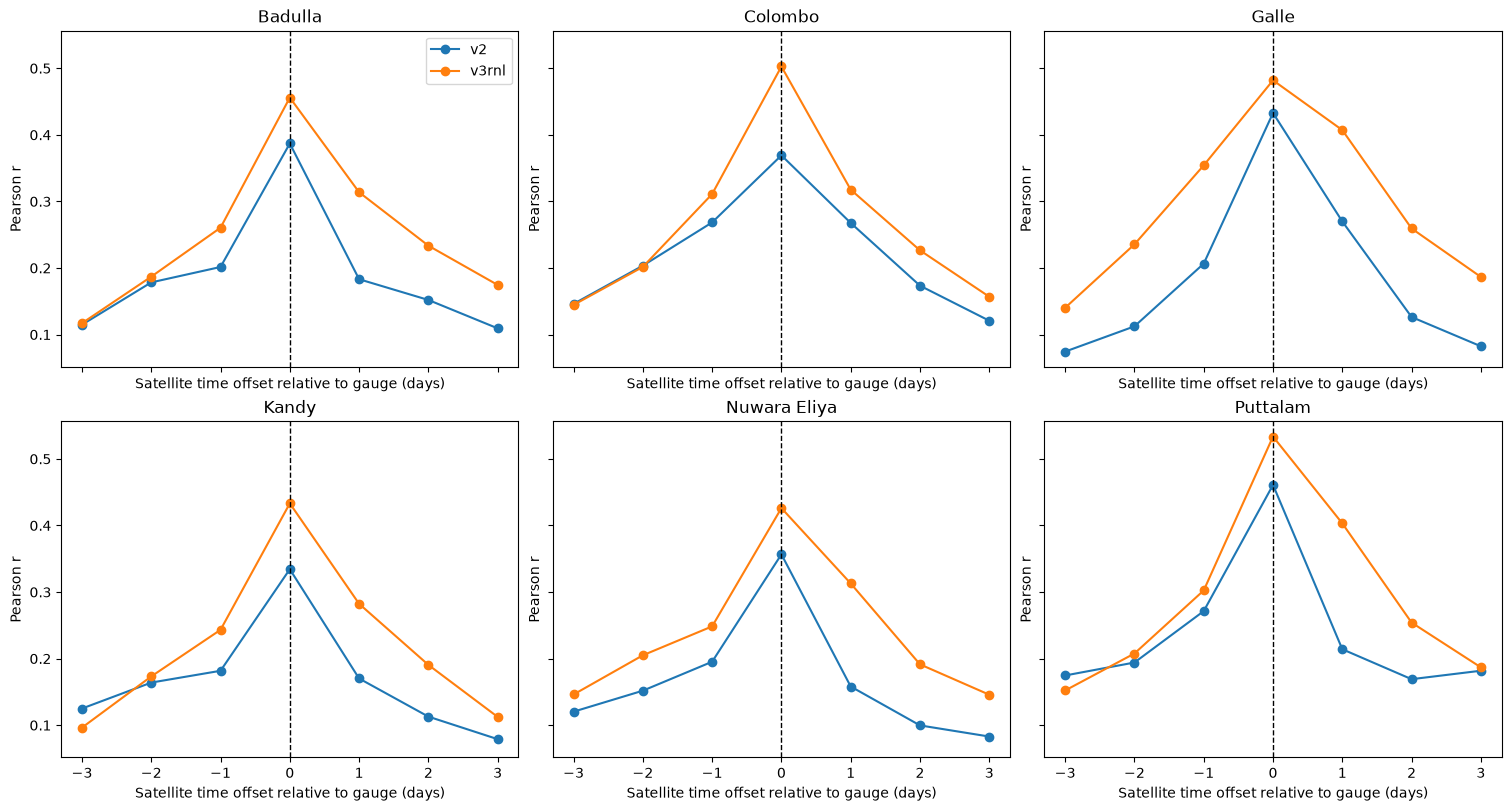

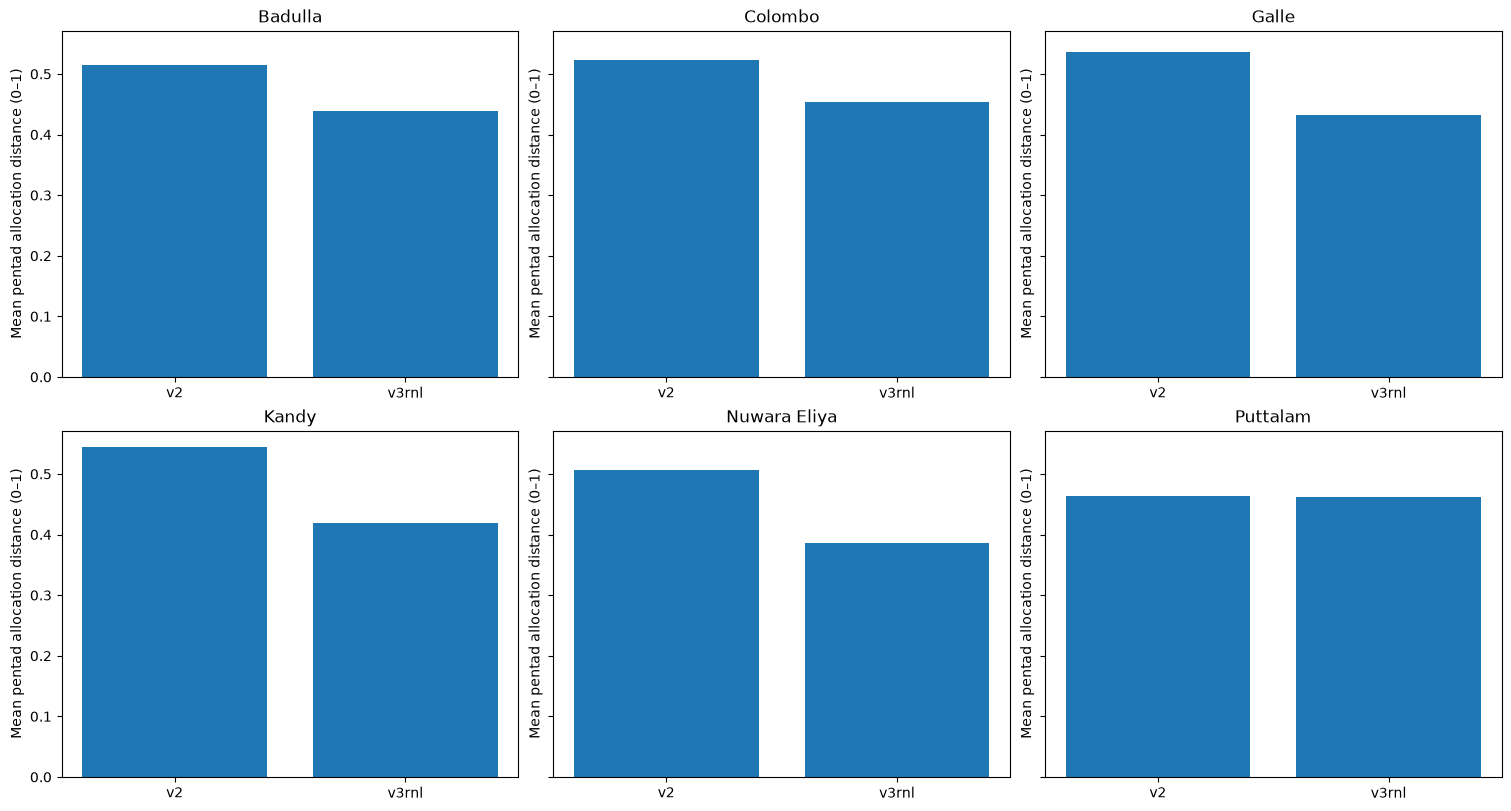

In [17]:
fig,axes=plt.subplots(2,3,figsize=(15,8),sharex=True,sharey=True,constrained_layout=True)
for ax,station in zip(axes.flat,sorted(test.Station.unique())):
    for v in ('v2','v3rnl'):
        d=lag_scores[(lag_scores.Station==station)&(lag_scores.Version==v)&lag_scores.Method.eq('Point_mm')]
        ax.plot(d.Lag_days,d.Pearson,marker='o',label=v)
    ax.axvline(0,color='k',ls='--',lw=1)
    ax.set_title(station);ax.set_xlabel('Satellite time offset relative to gauge (days)');ax.set_ylabel('Pearson r')
axes[0,0].legend();plt.show()

fig,axes=plt.subplots(2,3,figsize=(15,8),constrained_layout=True,sharey=True)
for ax,station in zip(axes.flat,sorted(test.Station.unique())):
    d=allocation_summary[(allocation_summary.Station==station)&allocation_summary.Method.eq('Point_mm')]
    ax.bar(d.Version,d.Mean_Total_Variation)
    ax.set_title(station);ax.set_ylabel('Mean pentad allocation distance (0–1)')
plt.show()


## 10. Weekly, monthly, and normalized cumulative rainfall (complete periods only)

,Scale,Station,Version,Method,N,Bias,MAE,RMSE,Pearson,Spearman
0,weekly,Badulla,v2,Point_mm,312,4.167,22.154,31.732,0.645,0.617
3,weekly,Badulla,v3rnl,Point_mm,312,3.291,19.071,28.650,0.726,0.699
6,weekly,Colombo,v2,Point_mm,312,-2.660,28.881,45.656,0.658,0.723
9,weekly,Colombo,v3rnl,Point_mm,312,3.345,26.461,39.684,0.752,0.782
12,weekly,Galle,v2,Point_mm,313,-4.816,30.096,46.677,0.637,0.636
15,weekly,Galle,v3rnl,Point_mm,313,-0.491,25.718,39.681,0.746,0.706
18,weekly,Kandy,v2,Point_mm,311,4.900,26.764,39.617,0.544,0.591
21,weekly,Kandy,v3rnl,Point_mm,311,1.299,22.380,34.269,0.609,0.685
24,weekly,Nuwara Eliya,v2,Point_mm,301,6.897,27.531,40.742,0.576,0.654
27,weekly,Nuwara Eliya,v3rnl,Point_mm,301,-1.238,24.067,35.088,0.625,0.676


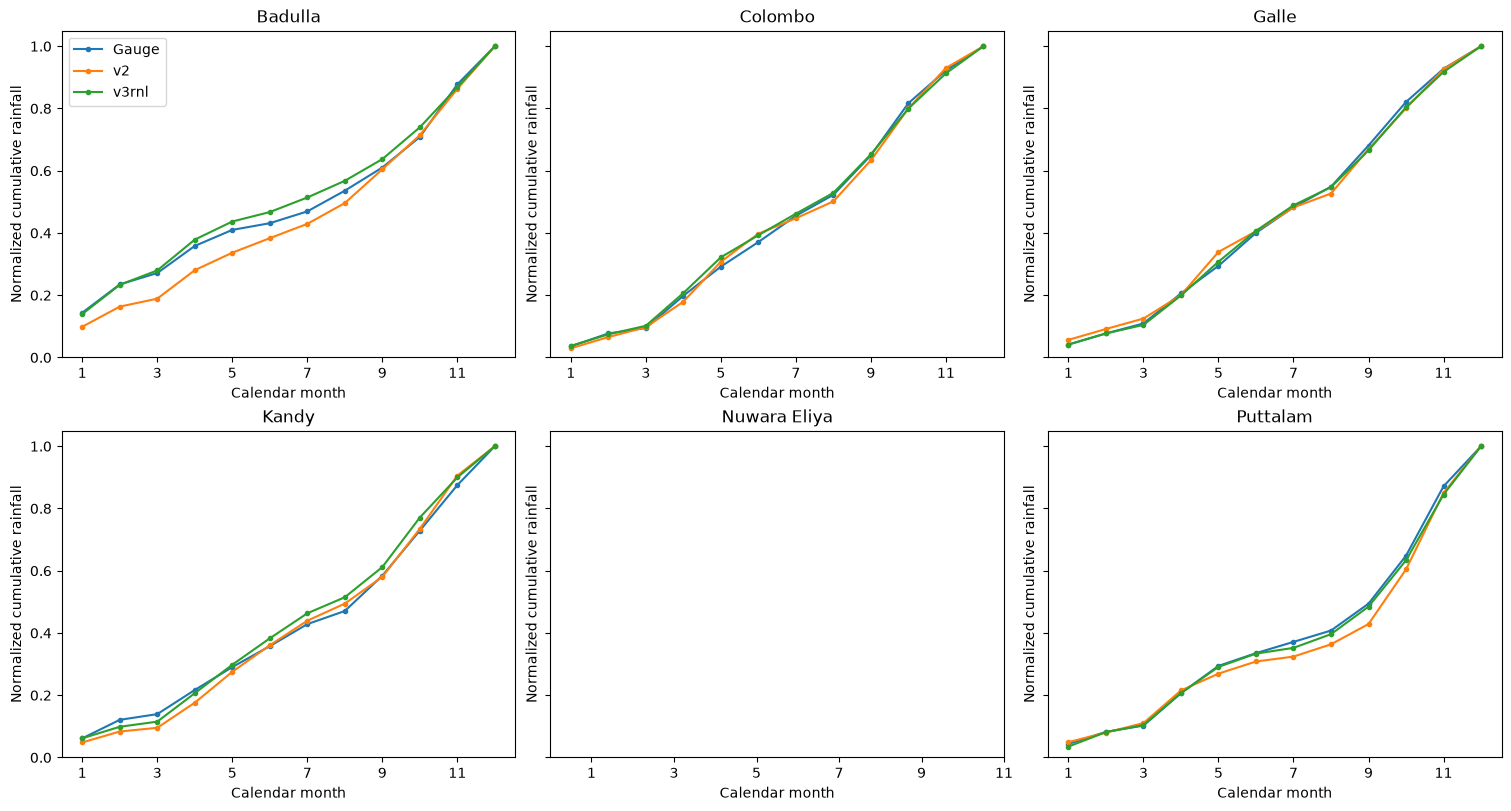

In [19]:
def complete_period_totals(d,scale):
    x=d.copy()
    if scale=='weekly':
        x['Period']=x.Date-pd.to_timedelta(x.Date.dt.dayofweek,unit='D');x['Expected']=7
    elif scale=='monthly':
        x['Period']=x.Date.dt.to_period('M').dt.start_time;x['Expected']=x.Date.dt.days_in_month
    else:raise ValueError(scale)
    g=x.groupby(['Station','Period'],as_index=False).agg(
        Days=('Date','nunique'),Expected=('Expected','first'),
        **{c:(c,'sum') for c in numeric})
    return g[g.Days.eq(g.Expected)].copy()
weekly=complete_period_totals(test,'weekly')
monthly=complete_period_totals(test,'monthly')
period_scores=[]
for scale,data in [('weekly',weekly),('monthly',monthly)]:
    for station,d in data.groupby('Station'):
        for version in ('v2','v3rnl'):
            for method in METHODS:
                period_scores.append({'Scale':scale,'Station':station,'Version':version,
                    'Method':method,**measures(d.Rainfall_mm,d[f'{version}_{method}'])})
period_scores=pd.DataFrame(period_scores)
display(period_scores.loc[period_scores.Method.eq('Point_mm')].round(3))

# Cumulative fraction only for complete years with all 12 complete months.
m=monthly.copy();m['Year']=m.Period.dt.year;m['Month']=m.Period.dt.month
complete_yrs=m.groupby(['Station','Year'])['Month'].transform('nunique').eq(12)
m=m.loc[complete_yrs].sort_values(['Station','Year','Month']).copy()
normalized=[]
for (station,year),d in m.groupby(['Station','Year']):
    for version,col in [('Gauge','Rainfall_mm'),('v2','v2_Point_mm'),('v3rnl','v3rnl_Point_mm')]:
        annual=d[col].sum()
        if annual>0:
            for month,cum in zip(d.Month,d[col].cumsum()/annual):
                normalized.append({'Station':station,'Year':year,'Month':month,'Version':version,
                                   'Cumulative_Fraction':cum})
normalized=pd.DataFrame(normalized)
if len(normalized):
    clim=normalized.groupby(['Station','Month','Version'],as_index=False)['Cumulative_Fraction'].mean()
    fig,axes=plt.subplots(2,3,figsize=(15,8),constrained_layout=True,sharey=True)
    for ax,station in zip(axes.flat,sorted(test.Station.unique())):
        d=clim[clim.Station.eq(station)]
        for ver,dd in d.groupby('Version'):
            ax.plot(dd.Month,dd.Cumulative_Fraction,marker='.',label=ver)
        ax.set_title(station);ax.set_xlabel('Calendar month');ax.set_ylabel('Normalized cumulative rainfall')
        ax.set_xticks(range(1,13,2));ax.set_ylim(0,1.05)
    axes[0,0].legend();plt.show()
else:
    print('No complete years available for normalized cumulative curves.')


## 11. Save *without overwriting* previous runs

New outputs go into `results/15_Temporal_Redistribution_Diagnostics/<timestamp>_<unique-id>/`. The source files and Notebooks 12–14 remain untouched.

In [21]:
run_dir=OUTPUT_ROOT/(datetime.now().strftime('%Y%m%d_%H%M%S')+'_'+uuid4().hex[:6])
run_dir.mkdir(parents=True,exist_ok=False)
tables={'matched_reporting_days':test,'daily_lag_scores':lag_scores,'complete_pentad_totals':pt,
        'pentad_total_scores':pentad_scores,'pentad_allocation':allocation,
        'pentad_allocation_summary':allocation_summary,'daily_on_complete_pentads':daily_complete_scores,
        'weekly_totals':weekly,'monthly_totals':monthly,'weekly_monthly_scores':period_scores,
        'normalized_cumulative':normalized}
for name,table in tables.items():
    table.to_csv(run_dir/(name+'.csv'),index=False)
print('Saved',len(tables),'CSV tables to:',run_dir)


Saved 11 CSV tables to: C:\Users\Asini Perera\CP Lab 1\CP Lab 2\Sri Lanka Rain Fall Reserach\results\15_Temporal_Redistribution_Diagnostics\20261102_230540_c87f7e


## 12. Scientific interpretation and limitations

1. **A pentad total may be accurate even when individual rain days are misallocated.** Compare complete-pentad total error with within-pentad rainfall fractions. This gives more evidence than a simple increase in correlation at longer scales.
2. **CHIRPS-style pentads are calendar-based, not arbitrary rolling windows.** The final pentad of each month is longer/shorter than five days depending on month length.
3. **Lagged correlations are descriptive**, and the preferred lag can differ by season and station. Do not optimize the lag on the test gauge data and then claim an unbiased improvement.
4. **Fractions are unstable when rainfall is near zero.** We exclude pentads with less than 5 mm in either series. Repeat with 1 and 10 mm as a robustness check.
5. **Only gauge–pixel comparisons are available.** They cannot isolate satellite data generation, gauge reading time, geography, or ERA5/CFS temporal redistribution errors as unique causes.
6. **Interpret satellite algorithm versions carefully:** CHIRPS v2 and CHIRPS v3 RNL do not use identical daily temporal-disaggregation inputs. Cite the relevant official products and describe the exact product extracted.
7. **The reporting period has already influenced previous research decisions.** Treat these analyses as exploratory/confirmatory diagnostics and be explicit in the report.

### Useful references
- Funk et al. (2015), *Scientific Data*: [CHIRPS original design](https://doi.org/10.1038/sdata.2015.66).
- [Google Earth Engine CHIRPS v2 daily dataset](https://developers.google.com/earth-engine/datasets/catalog/UCSB-CHG_CHIRPS_DAILY).
- [Google Earth Engine CHIRPS v3 RNL dataset](https://developers.google.com/earth-engine/datasets/catalog/UCSB-CHC_CHIRPS_V3_DAILY_RNL).
- Hyndman & Athanasopoulos, *Forecasting: Principles and Practice*, for correlation, time-series evaluation and aggregation: https://otexts.com/fpp3/.
